# Лабораторная работа № 1.3
---
«Кластерный анализ» 

Рязанцев Георгий Борисович

In [1]:
#Pfuheprf lfyys[]
from pandas import read_csv
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import distance as sci_distance
from sklearn import cluster as sk_cluster

data = read_csv('Clusters.csv',sep=';') #разделитель — ;
data.head()

,X11,X12,X13,X14,X15,X16,X17,X21,X22,X23,X31,X32,X41,X42
0,8.052,0.091,8.046,15.292,23.5,98.650,176.985,6.579314,21.2,3965,37.518713,261.8,0.006985,0.016450
1,-4.439,-0.108,-17.277,3.369,12.9,-4.574,-109.880,5.956182,30.5,2522,44.608950,37.9,0.005736,0.006310
2,-0.571,-0.013,-2.200,8.269,31.7,24.725,-23.799,2.221459,0.4,4863,10.448390,143.8,0.005238,0.015863
3,0.883,0.011,3.854,14.292,-4.2,49.021,53.809,6.096446,14.4,3511,36.778723,303.7,0.007943,0.017957
4,-0.479,-0.019,-5.200,3.177,7.2,20.326,-60.672,2.307553,5.2,3821,13.183659,49.7,0.006300,0.016841


Кластеризация проводится методом k-средних, который по сути
является алгоритмом неконтролируемого обучения, который ищет
закономерности в данных на основе сходства

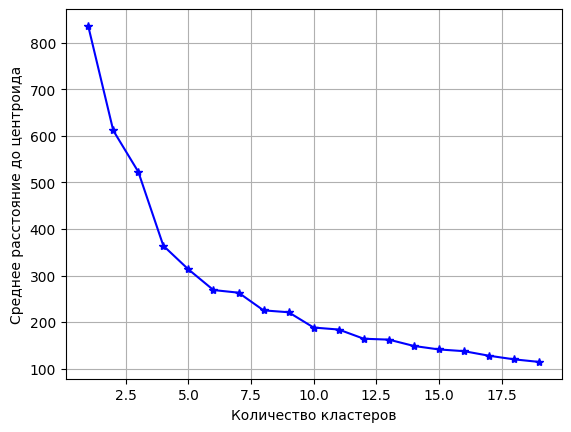

In [2]:
#определение количества кластеров
cdata = data
K = range(1, 20)
KM = (sk_cluster.KMeans(n_clusters=k).fit(cdata) for k in K)
centroids = (k.cluster_centers_ for k in KM)

D_k = (sci_distance.cdist(cdata, cent, 'euclidean') for cent in centroids)
dist = (np.min(D, axis=1) for D in D_k)
avgWithinSS = [sum(d) / cdata.shape[0] for d in dist]

plt.plot(K, avgWithinSS, 'b*-')
plt.grid(True)
plt.xlabel('Количество кластеров')
plt.ylabel('Среднее расстояние до центроида')
plt.show()

По рисунку видно, что оптимальным является значение k = 5. При
таком значении k регионы будут группироваться по пяти кластерам

In [3]:
#Кластерный анализ методом к-средних
n_clusters = 5
means_cluster = sk_cluster.KMeans(n_clusters=n_clusters, random_state=111)
columns = ["X11", "X12", "X13", "X14", "X15", "X16", "X17", "X21", "X22","X23","X31",
"X32","X41","X42"]
est = means_cluster.fit(data[columns])
clusters = est.labels_
data['cluster'] = clusters

#Выведем информацию о кластерах
for c in range(n_clusters):
    cluster_members=data[data['cluster'] == c] [:]
    print('Cluster{}(n={}):'.format(c, len(cluster_members)))
    #print('-'* 17)
print(data.groupby(['cluster']).mean())

Cluster0(n=24):
Cluster1(n=30):
Cluster2(n=9):
Cluster3(n=3):
Cluster4(n=12):
              X11       X12        X13        X14        X15        X16  \
cluster                                                                   
0       -0.162125 -0.001458  -1.396875  10.255417   3.375000  46.723000   
1       -0.144733 -0.014167  -5.683333  12.423800   5.473333  55.794133   
2        0.389889  0.011556   2.278667  13.022222  12.888889  63.548000   
3       -7.091000 -0.033000  -3.979667   8.064333  -8.466667  20.498333   
4       -2.383500 -0.017833 -24.062083   8.374167  16.575000  68.905333   

               X17       X21       X22          X23        X31         X32  \
cluster                                                                      
0         4.475542  3.187668  4.200000  3571.958333  26.867837  153.112500   
1        28.692100  3.704434  9.470000  2781.833333  30.616795  112.493333   
2        81.848556  5.452882  1.166667  4476.333333  22.197519  135.888889   
3     

In [4]:
import pandas as pd
import tkinter as tk
from tkinter import filedialog

In [5]:
a = data.groupby(['cluster']).mean()

df = pd.DataFrame(a)

root= tk.Tk()

c1 = tk.Canvas(root, width = 300, height = 300, bg = 'lightsteelblue2', relief='raised')
c1.pack()

def exportExcel ():
    global df

    export_file_path = filedialog.asksaveasfilename(defaultextension='.xlsx')
    df.to_excel (export_file_path, index = False, header=True)

In [6]:
#%pip install openpyxl

In [7]:
saveAsButtonExcel = tk.Button(text='Export Excel', command=exportExcel, bg='grey')
c1.create_window(150, 150, window=saveAsButtonExcel)

root.mainloop()

### Самостоятельная работа

In [8]:
# Нормализация данных

from sklearn.preprocessing import StandardScaler

columns = ["X11", "X12", "X13", "X14", "X15", "X16", "X17",
           "X21", "X22", "X23", "X31", "X32", "X41", "X42"]

scaler = StandardScaler()

data_norm = scaler.fit_transform(data[columns])

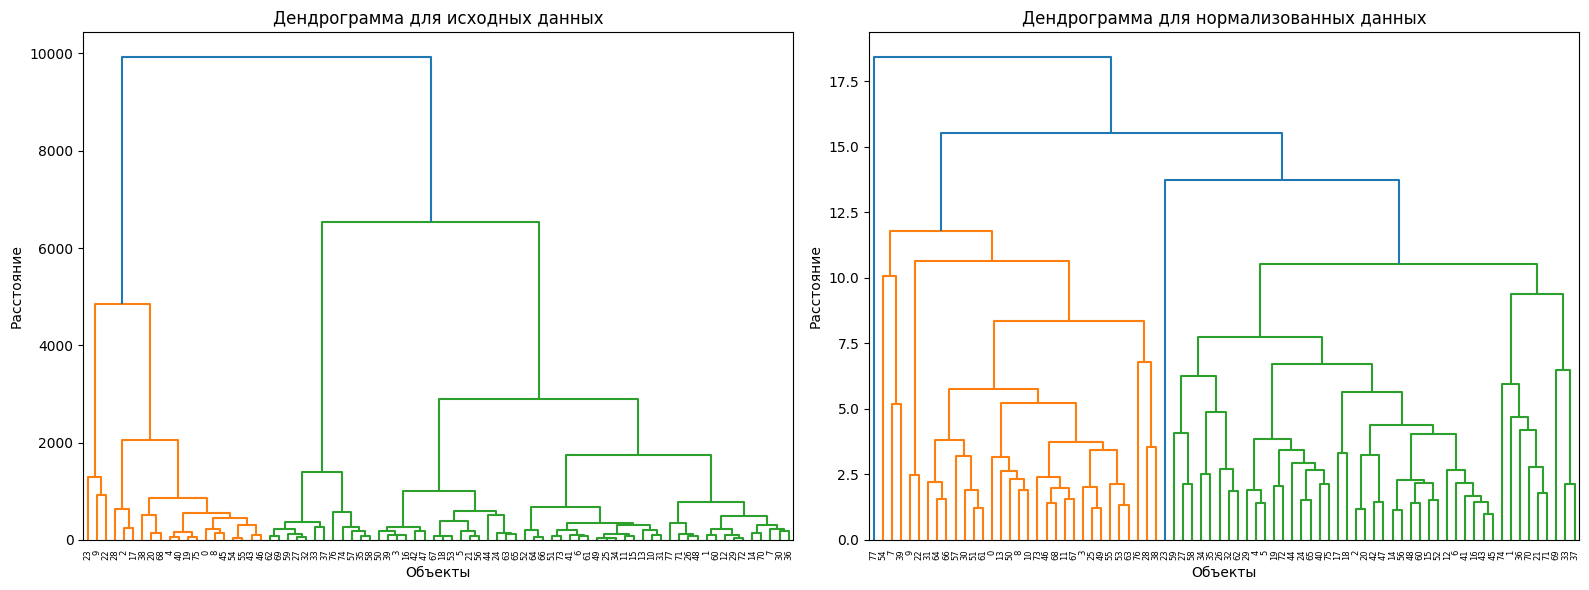

In [9]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

linked_norm = linkage(data_norm, method='ward')
linked = linkage(data, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Исходные данные
dendrogram(linked, ax=axes[0])
axes[0].set_title('Дендрограмма для исходных данных')
axes[0].set_xlabel('Объекты')
axes[0].set_ylabel('Расстояние')

# Нормализованные данные
dendrogram(linked_norm, ax=axes[1])
axes[1].set_title('Дендрограмма для нормализованных данных')
axes[1].set_xlabel('Объекты')
axes[1].set_ylabel('Расстояние')

plt.tight_layout()
plt.show()

In [15]:
data_norm = pd.DataFrame(data_norm, columns=columns, index=data.index)
cluster_3 = data[data['cluster'] == 3]
cluster_3_norm = data_norm.loc[data['cluster'] == 3, columns]

columns = ["X23", "X31", "X32", "X41", "X42"] #не все признаки

print(f"Кластер 3 (исходные данные): \n{cluster_3[columns]}\n")
print(f"Кластер 3 (нормализованные данные): \n{cluster_3_norm[columns]}")

Кластер 3 (исходные данные): 
     X23         X31     X32       X41       X42
9   5712   17.271467   841.2  0.009403  0.014550
22  6550    4.261518  1205.7  0.006414  0.014556
23  6559  160.200169     9.3  0.007494  0.023827

Кластер 3 (нормализованные данные): 
         X23       X31       X32       X41       X42
9   2.349419 -0.564151  3.586205  0.077218 -0.768762
22  3.120425 -1.160326  5.444686 -0.681157 -0.767341
23  3.128706  5.985490 -0.655413 -0.407188  1.306393


После нормализации обьекты 9 и 22 остались рядом, как и при ненормализованных данных, а 23 в свою очередь отдалился, т.к. изначально был близок ошибочно

В ненормализованных данных признак X23 играл большую роль просто из-за больших чисел, и обьект 23 был похож на 9 и 22 преимущественно по этому признаку (X23)

После нормализации влияние всех остальных признаков (в случае с обьектами 9,22 и 23 — более различающихся признаков) увеличилось, и следовательно обьект 23 определился в отдельный кластер 

In [12]:

data_norm.describe()

,X11,X12,X13,X14,X15,X16,X17,X21,X22,X23,X31,X32,X41,X42
count,7.800000e+01,78.000000,78.000000,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01,7.800000e+01
mean,4.697097e-17,0.000000,0.000000,-1.024821e-16,-3.416071e-17,5.693451e-18,4.270089e-17,-2.594079e-16,-4.127752e-17,-1.565699e-17,-1.494531e-16,-6.120460e-17,1.099548e-15,1.184238e-15
std,1.006473e+00,1.006473,1.006473,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00,1.006473e+00
min,-6.398197e+00,-7.641109,-6.198311,-2.415839e+00,-3.094811e+00,-1.162370e+00,-1.298451e+00,-8.544217e-01,-3.024192e+00,-1.926996e+00,-1.311496e+00,-2.289550e+00,-9.795856e-01,-2.611835e+00
25%,1.218643e-03,-0.158578,-0.028592,-4.766399e-01,-5.936019e-01,-5.890951e-01,-7.097378e-01,-3.937366e-01,-5.274824e-01,-5.022910e-01,-5.466125e-01,-5.675880e-01,-4.709536e-01,-6.029571e-01
50%,1.850958e-01,0.139890,0.239915,-1.081447e-01,7.048412e-02,-1.797924e-01,-1.469715e-01,-1.594990e-01,-1.257473e-01,-1.098876e-01,-1.761682e-01,-2.877961e-01,-2.116759e-01,-1.081520e-01
75%,2.971327e-01,0.351595,0.451756,4.512540e-01,5.290845e-01,3.285052e-01,3.416925e-01,8.398115e-02,2.313506e-01,5.463416e-01,2.738000e-01,3.273634e-01,7.654610e-02,5.811007e-01
max,2.138593e+00,1.382351,1.000169,6.119539e+00,3.143243e+00,5.731814e+00,4.877699e+00,8.089830e+00,2.903633e+00,3.128706e+00,5.985490e+00,5.444686e+00,5.871678e+00,4.055022e+00


In [13]:
data.describe()

,X11,X12,X13,X14,X15,X16,X17,X21,X22,X23,X31,X32,X41,X42,cluster
count,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000,78.000000
mean,-0.699987,-0.008577,-6.207705,11.034962,6.855128,54.557269,18.703897,3.626358,6.106410,3158.435897,29.582582,137.844872,0.009099,0.017986,1.346154
std,4.118893,0.072501,21.588920,8.808456,18.490023,51.200547,99.669647,3.026589,8.455435,1093.926617,21.963618,197.397419,0.003966,0.004499,1.365882
min,-26.884000,-0.559000,-139.162000,-10.108000,-50.000000,-4.574000,-109.880000,1.057005,-19.300000,1064.000000,0.962620,-311.200000,0.005238,0.006310,0.000000
25%,-0.695000,-0.020000,-6.821000,6.863500,-4.050000,24.589250,-51.580500,2.442343,1.675000,2612.500000,17.654200,26.525000,0.007243,0.015291,0.000000
50%,0.057500,0.001500,-1.061500,10.088500,8.150000,45.411000,4.149500,3.146725,5.050000,3039.000000,25.738174,81.400000,0.008264,0.017503,1.000000
75%,0.516000,0.016750,3.482500,14.984250,16.575000,71.268750,52.541250,3.878900,8.050000,3752.250000,35.557548,202.050000,0.009400,0.020584,2.000000
max,8.052000,0.091000,15.246000,64.592000,64.600000,346.142000,501.736000,27.953490,30.500000,6559.000000,160.200169,1205.700000,0.032237,0.036114,4.000000
